# TP1 — Comptage des mots

## 1. Version Python séquentielle

### Objectif
Implémenter un algorithme permettant de compter le nombre d'occurrences de chaque mot dans un fichier texte.

Cette première méthode utilise un dictionnaire Python pour associer chaque mot à son nombre d'apparitions.

Nous commencerons par un petit fichier afin de vérifier le fonctionnement de l'algorithme, avant de réaliser des tests sur des fichiers plus volumineux.

In [1]:

# Création d'un fichier de test
mots = ["chat", "chien", "chat", "oiseau", "chien", "chat"]

with open("mots.txt", "w", encoding="utf-8") as fichier:
    for mot in mots:
        fichier.write(mot + "\n")

print("Fichier mots.txt créé avec succès !")


Fichier mots.txt créé avec succès !


open("mots.txt", "w") crée un fichier en mode écriture.

for mot in mots parcourt les six éléments de la liste.

fichier.write(mot + "\n") écrit chaque mot sur une nouvelle ligne.

with ferme automatiquement le fichier après l'écriture.

In [2]:

def compter_occurrences(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}

    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


La méthode get(mot, 0) récupère le compteur actuel du mot ou renvoie zéro lorsque celui-ci n'existe pas encore.

In [3]:

# Exécution de l'algorithme
resultats = compter_occurrences("mots.txt")

# Affichage des résultats
for mot, nb in sorted(
    resultats.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{mot} : {nb}")

# Vérification automatique
assert resultats == {
    "chat": 3,
    "chien": 2,
    "oiseau": 1
}

print("Test réussi !")


chat : 3
chien : 2
oiseau : 1
Test réussi !


### Génération des jeux de données

Afin de comparer les performances des trois méthodes,
nous générons plusieurs fichiers de tailles différentes.

Chaque ligne contient un seul mot choisi aléatoirement
dans un vocabulaire prédéfini.

Le fichier initial contient N lignes. Les fichiers suivants
sont obtenus en répétant ces N lignes m fois.

Cette méthode garantit que les fichiers conservent
la même distribution des mots.


In [4]:

from pathlib import Path
import random

N = 1000
multiplicateurs = [1, 10, 100]

vocabulaire = [
    "chat", "chien", "oiseau", "maison",
    "voiture", "arbre", "soleil", "livre"
]

# Créer un dossier pour les fichiers
dossier = Path("donnees")
dossier.mkdir(exist_ok=True)

# Générer les N lignes initiales
random.seed(42)

mots_base = [
    random.choice(vocabulaire)
    for _ in range(N)
]

# Création des fichiers par duplication
for m in multiplicateurs:

    chemin = dossier / f"mots_{m}xN.txt"

    with open(chemin, "w", encoding="utf-8") as f:
        for _ in range(m):
            for mot in mots_base:
                f.write(mot + "\n")

    print(f"{chemin} : {N * m} lignes")


donnees/mots_1xN.txt : 1000 lignes
donnees/mots_10xN.txt : 10000 lignes
donnees/mots_100xN.txt : 100000 lignes


In [5]:

# Vérification des fichiers générés

for m in multiplicateurs:
    chemin = dossier / f"mots_{m}xN.txt"

    with open(chemin, "r", encoding="utf-8") as f:
        nb_lignes = sum(1 for ligne in f)

    assert nb_lignes == N * m

    print(f"m = {m} : {nb_lignes} lignes - OK")


m = 1 : 1000 lignes - OK
m = 10 : 10000 lignes - OK
m = 100 : 100000 lignes - OK


### Mesure des performances de la version séquentielle

Nous mesurons le temps d'exécution de l'algorithme sur
plusieurs fichiers de tailles croissantes.

Chaque expérience est répétée 7 fois et nous retenons
le temps médian.

Le temps mesuré comprend la lecture du fichier et
le comptage des occurrences, sans l'affichage des résultats.

Nous vérifions également l'exactitude du comptage.

In [6]:

import time
from statistics import median

resultats_v1 = []

# Comptage du fichier de référence
reference = compter_occurrences(
    dossier / "mots_1xN.txt"
)

for m in multiplicateurs:
    chemin = dossier / f"mots_{m}xN.txt"
    mesures = []

    # Répéter le test 7 fois
    for _ in range(7):
        debut = time.perf_counter()

        compte = compter_occurrences(chemin)

        fin = time.perf_counter()
        mesures.append(fin - debut)

    # Vérifier l'exactitude du résultat
    attendu = {
        mot: nb * m
        for mot, nb in reference.items()
    }
    assert compte == attendu

    temps_median = median(mesures)

    # Conserver les résultats
    resultats_v1.append({
        "m": m,
        "lignes": N * m,
        "temps_s": temps_median
    })

    print(
        f"{N*m:>7} lignes | "
        f"Temps médian : {temps_median:.6f} s | "
        f"Résultat correct"
    )


   1000 lignes | Temps médian : 0.000383 s | Résultat correct
  10000 lignes | Temps médian : 0.003490 s | Résultat correct
 100000 lignes | Temps médian : 0.043296 s | Résultat correct


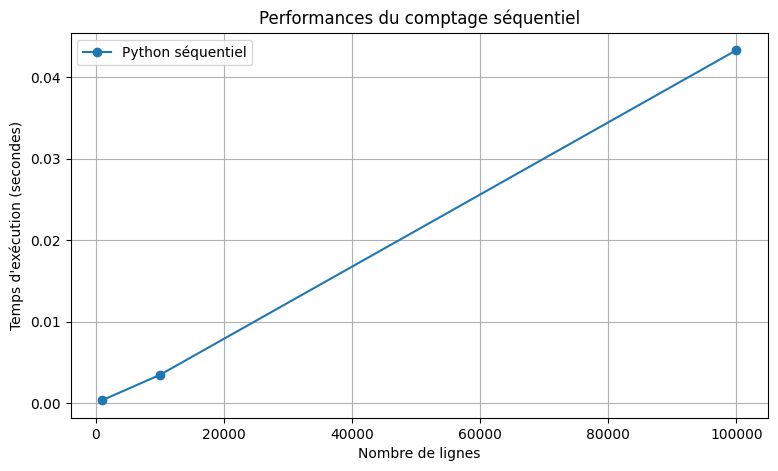

In [7]:

import matplotlib.pyplot as plt

tailles = [r["lignes"] for r in resultats_v1]
temps = [r["temps_s"] for r in resultats_v1]

plt.figure(figsize=(9, 5))

plt.plot(tailles, temps, marker="o", label="Python séquentiel")

plt.xlabel("Nombre de lignes")
plt.ylabel("Temps d'exécution (secondes)")
plt.title("Performances du comptage séquentiel")
plt.grid(True)
plt.legend()
plt.show()


### Analyse des performances de la version séquentielle

Les résultats montrent que le temps d'exécution augmente avec la taille du fichier. Pour 1 000 lignes, le traitement prend environ 0,0004 seconde, contre 0,0433 seconde pour 100 000 lignes.

Cette évolution est cohérente avec une complexité temporelle moyenne O(n), puisque l'algorithme parcourt les mots une seule fois pour mettre à jour leurs occurrences dans un dictionnaire.

Les écarts à une proportionnalité parfaite peuvent s'expliquer par les fluctuations de l'environnement Colab, la gestion de la mémoire et les opérations de lecture des fichiers.

Cette méthode constitue une référence pour les prochaines comparaisons avec le pseudo-MapReduce et Hadoop MapReduce.

## 2. Version Pseudo-MapReduce

### Objectif

Implémenter un programme de comptage des mots en reproduisant les trois phases du modèle MapReduce :

- **Map** : transformation des mots en paires (clé, valeur).
- **Shuffle** : regroupement des valeurs par clé.
- **Reduce** : agrégation des valeurs pour calculer les occurrences.

Cette implémentation fonctionne localement et ne réalise pas de traitement distribué.

In [8]:

from collections import defaultdict

# Phase 1 : MAP
def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]


# Phase 2 : SHUFFLE
def shuffle(mapped_data):
    grouped = defaultdict(list)

    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)

    return grouped


# Phase 3 : REDUCE
def reducer(grouped_data):
    reduced = {}

    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)

    return reduced


In [9]:

# Lire le fichier de test
with open("mots.txt", "r", encoding="utf-8") as f:
    lignes = f.readlines()

# Phase MAP
mapped = []

for ligne in lignes:
    mapped.extend(mapper(ligne))

print("MAP :", mapped)

# Phase SHUFFLE
grouped = shuffle(mapped)
print("\nSHUFFLE :", dict(grouped))

# Phase REDUCE
reduced = reducer(grouped)
print("\nREDUCE :", reduced)


MAP : [('chat', 1), ('chien', 1), ('chat', 1), ('oiseau', 1), ('chien', 1), ('chat', 1)]

SHUFFLE : {'chat': [1, 1, 1], 'chien': [1, 1], 'oiseau': [1]}

REDUCE : {'chat': 3, 'chien': 2, 'oiseau': 1}


In [10]:

def compter_occurrences_mapreduce(fichier):

    # MAP
    mapped = []

    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))

    # SHUFFLE
    grouped = shuffle(mapped)

    # REDUCE
    reduced = reducer(grouped)

    return reduced


# Test de la version 2
resultats_v2_test = compter_occurrences_mapreduce("mots.txt")

# Vérification avec la version 1
assert resultats_v2_test == resultats

print("Résultat :", resultats_v2_test)
print("Version 2 validée : mêmes résultats que la version 1 !")


Résultat : {'chat': 3, 'chien': 2, 'oiseau': 1}
Version 2 validée : mêmes résultats que la version 1 !


In [11]:

# Mesure des performances de la version 2

resultats_v2 = []

for m in multiplicateurs:
    chemin = dossier / f"mots_{m}xN.txt"
    mesures = []

    # Répéter 7 fois pour obtenir un temps médian
    for _ in range(7):

        debut = time.perf_counter()

        compte = compter_occurrences_mapreduce(chemin)

        fin = time.perf_counter()

        mesures.append(fin - debut)

    # Vérifier que le comptage est correct
    attendu = {
        mot: nb * m
        for mot, nb in reference.items()
    }

    assert compte == attendu

    temps_median = median(mesures)

    resultats_v2.append({
        "m": m,
        "lignes": N * m,
        "temps_s": temps_median
    })

    print(
        f"{N*m:>7} lignes | "
        f"Temps médian : {temps_median:.6f} s | "
        f"Résultat correct"
    )


   1000 lignes | Temps médian : 0.001162 s | Résultat correct
  10000 lignes | Temps médian : 0.013177 s | Résultat correct
 100000 lignes | Temps médian : 0.124828 s | Résultat correct


In [12]:

print(f"{'Lignes':>10} | {'Python (ms)':>14} | {'MapReduce (ms)':>16}")
print("-" * 46)

for v1, v2 in zip(resultats_v1, resultats_v2):

    assert v1["lignes"] == v2["lignes"]

    t1 = v1["temps_s"] * 1000
    t2 = v2["temps_s"] * 1000

    print(
        f"{v1['lignes']:>10} | "
        f"{t1:>14.3f} | "
        f"{t2:>16.3f}"
    )


    Lignes |    Python (ms) |   MapReduce (ms)
----------------------------------------------
      1000 |          0.383 |            1.162
     10000 |          3.490 |           13.177
    100000 |         43.296 |          124.828


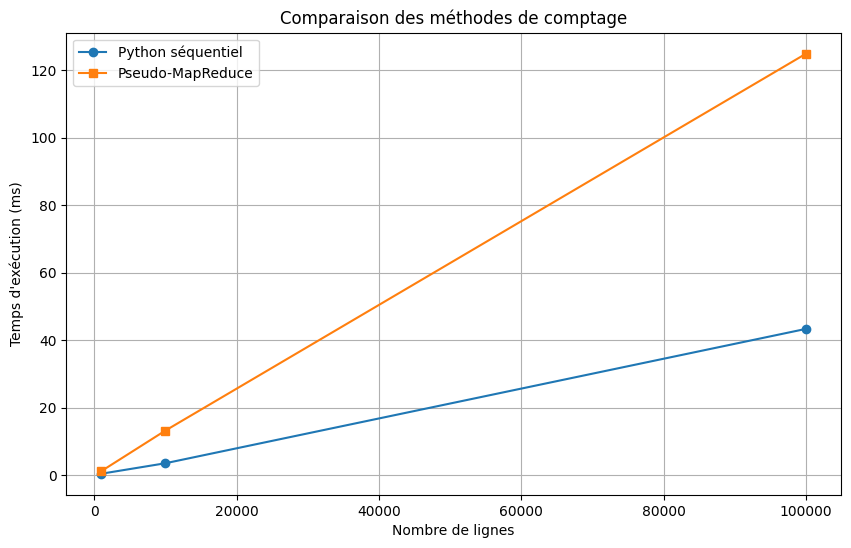

In [13]:

import matplotlib.pyplot as plt

# Tailles des fichiers
tailles = [r["lignes"] for r in resultats_v1]

# Temps en millisecondes
temps_v1 = [r["temps_s"] * 1000 for r in resultats_v1]
temps_v2 = [r["temps_s"] * 1000 for r in resultats_v2]

plt.figure(figsize=(10, 6))

plt.plot(
    tailles, temps_v1,
    marker="o",
    label="Python séquentiel"
)

plt.plot(
    tailles, temps_v2,
    marker="s",
    label="Pseudo-MapReduce"
)

plt.xlabel("Nombre de lignes")
plt.ylabel("Temps d'exécution (ms)")
plt.title("Comparaison des méthodes de comptage")
plt.grid(True)
plt.legend()
plt.show()


### Comparaison des performances : Python séquentiel et pseudo-MapReduce

Les résultats montrent que la version Python séquentielle est plus rapide que le pseudo-MapReduce pour les trois tailles de fichiers testées.

Pour 100 000 lignes, le temps d'exécution est de 43,296 ms pour Python séquentiel contre 124,828 ms pour le pseudo-MapReduce, soit environ 2,88 fois plus de temps.

Cette différence s'explique par les opérations supplémentaires de la méthode MapReduce : création des paires clé-valeur, regroupement des valeurs puis agrégation.

Les deux méthodes présentent une évolution compatible avec une complexité temporelle moyenne O(n), mais avec des coûts d'exécution différents.

Le pseudo-MapReduce présente surtout un intérêt pédagogique pour comprendre l'organisation des traitements distribués. Son exécution locale ne bénéficie pas des possibilités de parallélisation offertes par Hadoop.